In [1]:
import pandas as pd
import seaborn as sns
import os
import glob
import matplotlib.pyplot as plt
import sys
scripts = 'Scripts'
import importlib
sys.path.append(scripts)
import SingleCellPython
import BLASTanalysis
import numpy as np
dataFolder = os.path.join('Sequencing','scRNAseq')
sns.set_style("white")
sns.set_style("ticks")
import scipy
from scipy import stats
colormap = 'colorblind'
colors = sns.color_palette(colormap, 8)
segments = ['PB2','PB1','PA',  'HA','NP','NA','M_mRNA','NS_mRNA']
fluColors = {}
alternateFlu = ['PB2_mRNA','PB1_mRNA','PA_mRNA',  'HA_mRNA','NP_mRNA','NA_mRNA','M_mRNA','NS_mRNA']
otherfluColors = {}
for color, segment in enumerate(segments):
    fluColors[segment] = colors[color]
for color, segment in enumerate(alternateFlu):
    otherfluColors[segment] = colors[color]
typeI = ['IFNB1', 'IFNA1', 'IFNA2', 'IFNA4', 'IFNA5', 'IFNA6', 'IFNA7', 'IFNA8','IFNA10', 'IFNA13', 'IFNA14', 'IFNA16', 'IFNA17' ]
typeIII = ['IL28A', 'IL28B', 'IL29']
#some ISG's identified in Mendes and Russell 2021
ISG = ['IFI27', 'OASL','IFIT2','ISG15','MX1']
#Threshold of positivity, likely would act similar to an FDR
quantileThresh = 0.99
from statsmodels.stats import multitest
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams.update({'font.size': 12, 'axes.titlesize':'medium',})
from scipy.stats import poisson
from multiprocessing import Pool
numProcessors = 4

# deletion annotation, of those called as splices

In [2]:
blastdb = 'Database/WSN_mRNA_BLAST/WSN_mRNA.fa'
resultsDir = os.path.join('Results', 'scRNAseq')
if not os.path.isdir(resultsDir):
    os.mkdir(resultsDir)
#blast variables for identifying junctions
percentIdentity = 90
wordSize = 10
gapOpen = 5
gapExtend = 2
eValue = 0.000001
outFormat = '"6 qseqid qlen qstart qend sstart send evalue sseqid qseq"'

prefix = {'DI':'human__human_flu_', 'IM':'human_flu_'}

In [3]:
#pull "spliced" flu reads as well as all unmapped
mSplices = [(52,741), (146,741)]
NSsplices = [(57,530)]
for sample in glob.glob(os.path.join('Sequencing','scRNAseq','*')):
    if os.path.basename(sample) in prefix.keys():
        outDir = os.path.join('Results','scRNAseq',os.path.basename(sample))
        if not os.path.isdir(outDir):
            os.mkdir(outDir)
        bamfile = os.path.join(sample, 'outs','possorted_genome_bam.bam')
        tempSam = os.path.join(outDir, 'temp.sam')
        !samtools view -H $bamfile > $tempSam
        for segment in alternateFlu:
            segment = prefix[os.path.basename(sample)] + segment
            !samtools view $bamfile $segment | awk '($6 ~ /N/)' >> $tempSam
        tempFasta = os.path.join(outDir, 'temp.fa')
        !samtools fasta $tempSam > $tempFasta
        outfile = os.path.join(outDir, 'deletionJunctions.blastout') 
        arguments = ' '.join(['-db', blastdb, '-query', tempFasta, '-perc_identity', str(percentIdentity), 
                     '-num_threads', str(numProcessors), '-word_size', str(wordSize), '-gapopen', str(gapOpen),
                     '-gapextend', str(gapExtend), '-evalue', str(eValue), '-outfmt', outFormat,
                     '-out', outfile])
        !blastn $arguments
        outfile2 = os.path.join(outDir, 'deletionJunctions_junctions.tsv')
                              
        
        BLASTanalysis.delAnnotate(outfile, outfile2, os.path.join('Database', 'WSN_mRNA_BLAST','WSN_mRNA.fa'))

        outfile3= os.path.join(outDir, 'deletionJunctions_junctions_barcodes.tsv')
        BLASTanalysis.delAssign(tempSam, outfile2, outfile3)
        !rm -f $tempSam
        !rm -f $tempFasta

        deletions = pd.read_csv(outfile3, encoding='utf8' , sep='\t')
        for splice in mSplices:
            deletions = deletions.loc[~((deletions.segment == 'M_mRNA') & (deletions.fiveprime == splice[0]) & (
                                            deletions.threeprime == splice[1]))]
        for splice in NSsplices:
            deletions = deletions.loc[~((deletions.segment == 'NS_mRNA') & (deletions.fiveprime == splice[0]) & (
                                            deletions.threeprime == splice[1]))]
        deletions = deletions[['barcode', 'segment', 'fiveprime','threeprime', 'count']]
        deletions.to_csv(outfile3, sep='\t')

samtools fasta: Coordinate sorted file.  Read pairs may be out of order
[M::bam2fq_mainloop] discarded 0 singletons
[M::bam2fq_mainloop] processed 3169 reads
samtools fasta: Coordinate sorted file.  Read pairs may be out of order
[M::bam2fq_mainloop] discarded 0 singletons
[M::bam2fq_mainloop] processed 22 reads


# deletion annotation in unmapped reads

would need to be added to cell/barcode matrix as extra counts, so kept separate. use cell magic as unmapped reads do contain a number of reads unmappable via BLAST (likely due to many N's) that throw errors. As these are excluded from output, and their presence isn't interesting, and filtering may introduce inadvertant bias, we have chosen to just suppress output so as not to crash the kernel.

In [5]:
%%capture
#pull "spliced" flu reads as well as all unmapped
mSplices = [(52,741), (146,741)]
NSsplices = [(57,530)]
for sample in glob.glob(os.path.join('Sequencing','scRNAseq','*')):
    if os.path.basename(sample) in prefix.keys():
        outDir = os.path.join('Results','scRNAseq',os.path.basename(sample))
        if not os.path.isdir(outDir):
            os.mkdir(outDir)
        bamfile = os.path.join(sample, 'outs','possorted_genome_bam.bam')
        tempSam = os.path.join(outDir, 'temp.sam')
        !samtools view -H $bamfile > $tempSam
        !samtools view $bamfile -f 4 >> $tempSam
        tempFasta = os.path.join(outDir, 'temp.fa')
        !samtools fasta $tempSam > $tempFasta
        outfile = os.path.join(outDir, 'deletionJunctionsUnMapped.blastout') 
        errorFile = os.path.join(outDir, 'deletionJunctionsUnMapped.blasterr') 
        arguments = ' '.join(['-db', blastdb, '-query', tempFasta, '-perc_identity', str(percentIdentity), 
                     '-num_threads', str(numProcessors), '-word_size', str(wordSize), '-gapopen', str(gapOpen),
                     '-gapextend', str(gapExtend), '-evalue', str(eValue), '-outfmt', outFormat,
                     '-out', outfile])
        !blastn $arguments 
        outfile2 = os.path.join(outDir, 'deletionJunctionsUnMapped_junctions.tsv')
                              
        
        BLASTanalysis.delAnnotate(outfile, outfile2, os.path.join('Database', 'WSN_mRNA_BLAST','WSN_mRNA.fa'))

        outfile3= os.path.join(outDir, 'deletionJunctionsUnMapped_junctions_barcodes.tsv')
        BLASTanalysis.delAssign(tempSam, outfile2, outfile3)
        !rm -f $tempSam
        !rm -f $tempFasta

        deletions = pd.read_csv(outfile3, encoding='utf8' , sep='\t')
        for splice in mSplices:
            deletions = deletions.loc[~((deletions.segment == 'M_mRNA') & (deletions.fiveprime == splice[0]) & (
                                            deletions.threeprime == splice[1]))]
        for splice in NSsplices:
            deletions = deletions.loc[~((deletions.segment == 'NS_mRNA') & (deletions.fiveprime == splice[0]) & (
                                            deletions.threeprime == splice[1]))]
        deletions = deletions[['barcode', 'segment', 'fiveprime','threeprime', 'count']]
        deletions.to_csv(outfile3, sep='\t')

# Thresholds, basic statistics

Process canine data

In [2]:
samples = {}
for sample in glob.glob(os.path.join(dataFolder, '*')):
    datafolder = os.path.join(sample, 'outs')
    canineRaw = os.path.join(datafolder, 'raw_gene_bc_matrices', 'canine')
    humanFluRaw =  os.path.join(datafolder, 'raw_gene_bc_matrices', 'human_flu') 
    processedHumanBarcodes = os.path.join(datafolder, 'filtered_gene_bc_matrices', 'human_flu','barcodes.tsv')
    processedCanineBarcodes = os.path.join(datafolder, 'filtered_gene_bc_matrices','canine','barcodes.tsv')

    canineData = SingleCellPython.MatrixToPanda(os.path.join(canineRaw, 'barcodes.tsv'), os.path.join(canineRaw, 'genes.tsv'),
                                                os.path.join(canineRaw,'matrix.mtx'),
                                               False, False)
    humanData = SingleCellPython.MatrixToPanda(os.path.join(humanFluRaw,  'barcodes.tsv'), os.path.join(humanFluRaw, 'genes.tsv'),
                                               os.path.join(humanFluRaw, 'matrix.mtx'),
                                               False, False)
    
    humanCells =  pd.read_csv(processedHumanBarcodes, names = ['cell'], sep='\t')
    canineCells = pd.read_csv(processedCanineBarcodes, names = ['cell'], sep='\t')
    
    acceptedCells = pd.concat([humanCells, canineCells])
                              
                              
    acceptedCells = acceptedCells.drop_duplicates().reset_index(drop=True)
    canineData['identity'] = 'canine'
    humanData['identity'] = 'human'
    canineData = canineData.merge(acceptedCells, on =['cell'])
    humanData = humanData.merge(acceptedCells, on =['cell'])
    samples[os.path.basename(sample)] = {'canineData':canineData, 'humanData':humanData, 'humCells':humanCells, 'canCells':canineCells}

In [3]:
for sample in samples:
    
    combined = pd.concat([samples[sample]['canineData'], samples[sample]['humanData']])
    combined = combined.groupby(['identity', 'cell']).UMI.sum().reset_index()
    combined = combined.pivot(index = 'cell', columns = 'identity', values = 'UMI').fillna(0).reset_index()
    combined['cell_identity'] = 'none'
    combined.loc[combined.cell.isin(samples[sample]['humCells'].cell),'cell_identity'] = 'human'
    combined.loc[combined.cell.isin(samples[sample]['canCells'].cell),'cell_identity'] = 'canine'
    combined.loc[(combined.cell.isin(samples[sample]['canCells'].cell)) & (combined.cell.isin(samples[sample]['humCells'].cell)),'cell_identity'] = 'both'
    samples[sample]['combined'] = combined

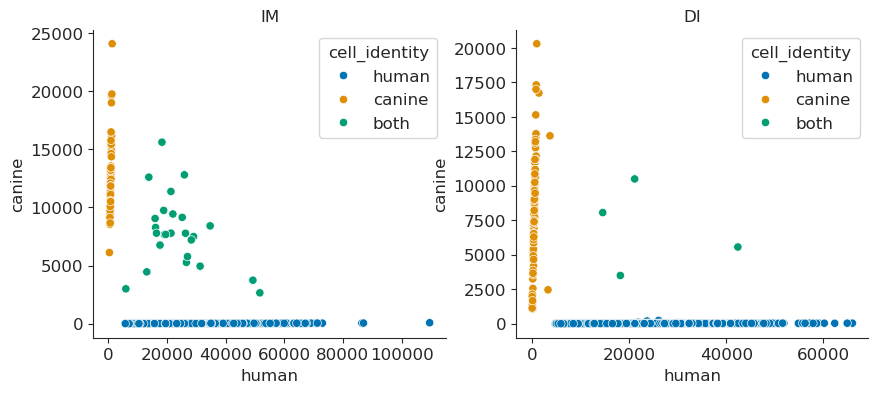

In [4]:
fig, axes = plt.subplots(nrows=1, ncols = len(samples.keys()), figsize=(10,4))
for ax,sample in enumerate(samples):
    axis = axes[ax]
    sns.scatterplot(data=samples[sample]['combined'], x="human", y="canine", hue = 'cell_identity', hue_order = ['human','canine','both'], palette=colors[:3], ax=axis)
    sns.despine()
    axis.title.set_text(sample)
plt.savefig(os.path.join('Figures','scRNAseq', 'original10xcellAnnotation.pdf'), format='pdf', bbox_inches = "tight")

In [5]:
for sample in samples:
    combined = samples[sample]['combined']
    doubles = len(combined[combined.cell_identity == 'both'])
    human = len(combined[combined.cell_identity == 'human']) + doubles
    canine = len(combined[combined.cell_identity == 'canine']) + doubles
    
    #calculate total number of droplets
    numDrop = (canine + doubles) * (human + doubles)/doubles
    #µ1
    µ1 = -np.log((numDrop - human -doubles)/numDrop)
    #µ2
    µ2 = -np.log((numDrop - canine - doubles)/numDrop)
    
    #frequency
    multiFreq = 1 - (((µ1 + µ2) * 2.718 ** (-µ1 + µ2))/(1 - 2.718**(-µ1 - µ2)))
    print("in sample %s" % sample)
    print("%s cells are human only" % human)
    print("%s cells are canine only" % canine)
    print("%s cells are doublets" % doubles)
    print("Then we may infer %s percent of emulsions are likely multiplets" % (round(multiFreq*100, 2)))

in sample IM
1639 cells are human only
114 cells are canine only
25 cells are doublets
Then we may infer 7.52 percent of emulsions are likely multiplets
in sample DI
2628 cells are human only
130 cells are canine only
4 cells are doublets
Then we may infer 1.27 percent of emulsions are likely multiplets


In [6]:
fluThresh = {}
for sample in samples:
    prefix = 'human_flu_'
    combined = samples[sample]['combined']
    nonDoubletList = combined[combined.cell_identity=='canine'].cell
    justCanineHuman = samples[sample]['humanData'].loc[samples[sample]['humanData'].cell.isin(nonDoubletList),]
    fluGenes = [prefix + segment for segment in segments]
    typeIgenes = [prefix + gene for gene in typeI]
    typeIIIgenes = [prefix + gene for gene in typeIII]
    print('sums canine')
    print(justCanineHuman[justCanineHuman.gene.isin(fluGenes)].UMI.max())
    print(justCanineHuman[justCanineHuman.gene.isin(typeIgenes)].UMI.max())
    print(justCanineHuman[justCanineHuman.gene.isin(typeIIIgenes)].UMI.max())
    print(justCanineHuman[justCanineHuman.gene.isin(['IFI6','ISG16'])].UMI.max())

    fluThresh[sample] = 1.5*justCanineHuman[justCanineHuman.gene.isin(fluGenes)].UMI.max()
    

sums canine
8
nan
nan
nan
sums canine
1
nan
nan
nan


Deletions? do we see any in canine cells or can we just use 1 as the cutoff?

In [7]:
deletionCalled = {}
deletionFrame = []
for sample in samples:
    prefix = 'human_flu_'
    combined = samples[sample]['combined']
    nonDoubletList = combined[combined.cell_identity=='canine'].cell
    justCanineHuman = samples[sample]['humanData'].loc[samples[sample]['humanData'].cell.isin(nonDoubletList),]
    deletionJunctions = pd.concat([pd.read_csv(file, sep='\t') for file in glob.glob(os.path.join('Results','scRNAseq',sample,'*barcodes.tsv'))])
    deletionJunctions['sample'] = sample
    justCanineHuman = deletionJunctions[deletionJunctions.barcode.isin(justCanineHuman.cell)] 
    if justCanineHuman['count'].max() ==  justCanineHuman['count'].max():
        deletionJunctions = deletionJunctions[deletionJunctions['count'] >= justCanineHuman['count'].max()*1.5]
    
    deletionFrame += [deletionJunctions]
deletionFrame = pd.concat(deletionFrame)

Don't need to use canine data, contamination  minimal, annotations solid.

In [8]:
samples = {}
for sample in glob.glob(os.path.join(dataFolder, '*')):
    datafolder = os.path.join(sample, 'outs')
    human =  os.path.join(datafolder, 'filtered_gene_bc_matrices', 'human_flu') 
  
    humanData = SingleCellPython.MatrixToPanda(os.path.join(human,  'barcodes.tsv'), os.path.join(human, 'genes.tsv'),
                                               os.path.join(human, 'matrix.mtx'),
                                               False, False)
    samples[os.path.basename(sample)] = humanData

In [9]:
prefixSamples = ['DI','IM']
for sample in prefixSamples:
    samples[sample]['gene'] = samples[sample]['gene'].str.slice(len('human_flu_'))

# ISG analysis

Simple scatter of ISG identified in Stevens et al. 2022 eLife.

In [10]:
ISGlist = pd.read_csv(os.path.join('Database','ISGlist.csv'))
ISGlist = ISGlist[ (ISGlist['log2(FC)'] > 1) & (ISGlist['P-adj'] < 0.1)]['Gene symbol']
graph = []
for sample in samples:
    currFrame = samples[sample].copy()
    depth = currFrame.UMI.sum()
    currFrame = currFrame[currFrame.gene.isin(ISGlist)].groupby(['gene']).sum().reset_index()
    currFrame['fraction of transcriptome'] = currFrame.UMI/depth
    currFrame['sample'] = sample
    graph +=[currFrame]
graph = pd.concat(graph).pivot_table(index = 'gene', columns = 'sample', values = 'fraction of transcriptome').reset_index().dropna()
graph['DI']= np.log2(graph.DI)
graph['IM'] = np.log2(graph.IM)

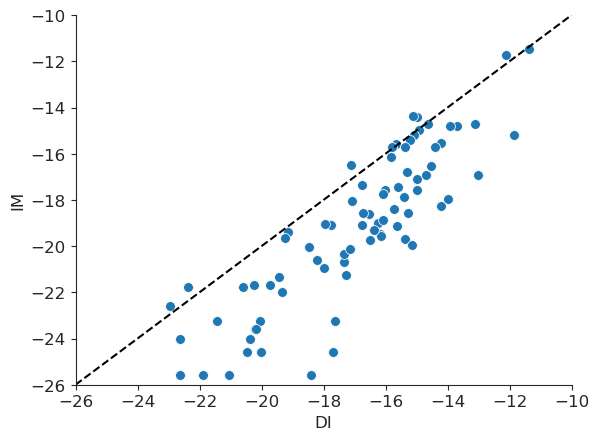

In [11]:
ax =sns.scatterplot(data=graph, x= 'DI', y = 'IM', s=50)
plt.ylim(-26,-10)
plt.xlim(-26,-10)
ax.axline((0, 0), slope=1, color='k', ls = '--', label='y = x')
sns.despine()
plt.savefig(os.path.join('Figures','scRNAseq', 'ISGpseudobulk.pdf'), format='pdf', bbox_inches = "tight")

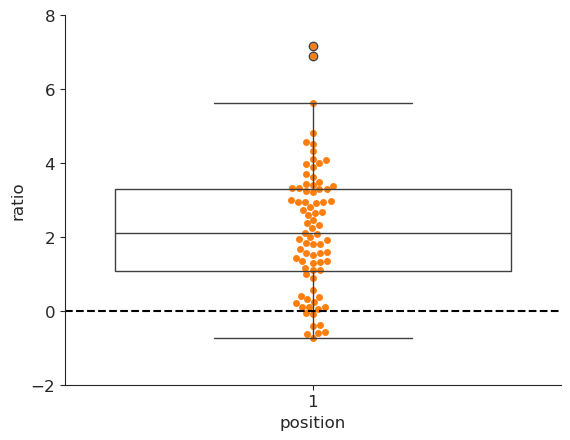

In [12]:
graph['position'] = 1
graph['ratio'] = graph.DI-graph.IM
sns.boxplot(data= graph, x="position", y="ratio",boxprops={'facecolor':'None'})
sns.swarmplot(x="position", y="ratio", data=graph, zorder=.5)
plt.axhline(y=0, color = 'k', ls='--')
plt.ylim(-2,8)
sns.despine()
stats.ttest_1samp(graph.ratio, popmean=0)
plt.savefig(os.path.join('Figures','scRNAseq', 'ISGpseudobulkBoxplot.pdf'), format='pdf', bbox_inches = "tight")

In [13]:
ISGlist = graph[(graph.DI > -16) | (graph.IM > -16)].sort_values('ratio').tail(12).gene.tolist() 
graph2 = []
for sample in samples:
    currFrame = samples[sample]
    depth = currFrame.groupby(['cell']).UMI.sum().reset_index()
    currFrame = currFrame[currFrame.gene.isin(ISGlist)].pivot_table(index='cell',values='UMI',columns = 'gene').reset_index().fillna(0)
    currFrame = currFrame.merge(depth, on='cell', how='right').fillna(0)
    currFrame[ISGlist] = currFrame[ISGlist].div(currFrame['UMI'], axis=0)
    currFrame['sample'] = sample
    graph2 +=[currFrame]
graph2 = pd.concat(graph2)
graph2 = graph2.melt( id_vars=['sample','cell'], value_vars=ISGlist, var_name='gene', value_name='fraction' )
graph2['fractionPlus'] = np.log2(graph2.fraction + 0.000005)

In [14]:
graph2['presence'] = graph2.fraction != 0
graph3 = graph2.groupby(['sample','gene']).presence.mean().reset_index()

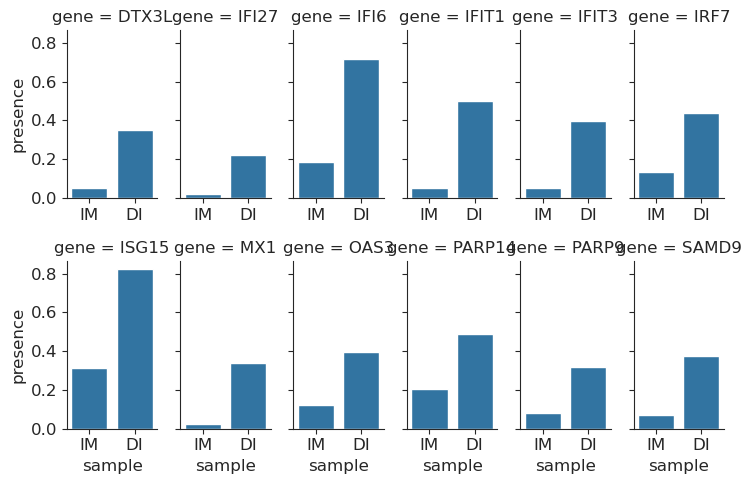

In [15]:
g = sns.FacetGrid(graph3, col="gene", height=2.5, aspect=0.5, col_wrap=6, sharex=False, sharey=True, col_order = sorted(list(set(graph3.gene))))
g.map(sns.barplot,'sample', 'presence',order= ['IM','DI'])


plt.savefig(os.path.join('Figures','scRNAseq', 'SelectISGdist_overview.pdf'), format='pdf', bbox_inches = "tight")


In [17]:
graph3 = []
for sample in samples:
    currFrame = samples[sample].copy()
    cells = pd.DataFrame({'cell':list(set(samples[sample]['cell']))})
    currFrame = currFrame[currFrame.gene.isin(ISGlist)].groupby(['cell','gene']).UMI.count().reset_index().pivot_table(values = 'gene', index = 'cell', columns = 'gene').reset_index().fillna(0)
    currFrame = currFrame.merge(cells, on='cell', how='right').fillna(0)
    currFrame['sample'] = sample
    graph3 += [currFrame]
graph3 = pd.concat(graph3)

In [18]:
pvals = []
for gene in sorted(ISGlist):
    contingency = pd.crosstab(graph3[gene],graph3['sample'] )
    ratio, pval = scipy.stats.fisher_exact(contingency)
    frequency = pd.crosstab(graph3['sample'], graph3[gene], normalize='index').stack().reset_index().rename(columns={0:'value'})
    print(gene)
    print(pval)
    pvals += [pval]

DTX3L
2.0473180920573516e-131
IFI27
3.321531692877331e-88
IFI6
1.0164763575141353e-262
IFIT1
7.859275889349961e-234
IFIT3
3.592974060644998e-157
IRF7
5.41982044060166e-103
ISG15
3.581133410042513e-251
MX1
2.647931071882923e-165
OAS3
5.304279604043289e-89
PARP14
2.1788209370269345e-79
PARP9
3.4346149011770074e-80
SAMD9
2.0880642556515744e-122


In [19]:
multitest.multipletests(pvals, alpha=0.05, method='fdr_bh', is_sorted=False, returnsorted=False)[1]

array([4.09463618e-131, 3.98583803e-088, 1.21977163e-261, 3.14371036e-233,
       8.62313775e-157, 8.12973066e-103, 2.14868005e-250, 7.94379322e-165,
       7.07237281e-089, 2.17882094e-079, 3.74685262e-080, 3.57953872e-122])

If we instead list as detects and non-detects, does presence of any given ISG higher expression of the others?
Calculate average frequency of detection if any given gene is present (use median to prevent non-detects from artificially lowering values)

also require detected in > 5% and <90% for numbers sake

In [23]:
ISGlist = pd.read_csv(os.path.join('Database','ISGlist.csv'))
ISGlist = ISGlist[ (ISGlist['log2(FC)'] > 1) & (ISGlist['P-adj'] < 0.1)]['Gene symbol']
newList = samples['DI'].copy()

numCells = len(set(newList.cell))
lowerLim = numCells * 0.05
upperLim = numCells * 0.95
newList = newList[newList.gene.isin(ISGlist)].groupby(['gene']).UMI.count().reset_index()
newList = newList[(newList.UMI >= lowerLim) & (newList.UMI <= upperLim)].gene

print(len(newList))
graph3 = []
for sample in ['DI']:
    currFrame = samples[sample].copy()
    depth = samples[sample].copy().groupby(['cell']).UMI.sum().reset_index().rename(columns = {'UMI':'depth'})
    currFrame = currFrame.merge(depth, on='cell', how='right').fillna(0)
    currFrame['fraction'] = currFrame.UMI/currFrame.depth
    currFrame = currFrame[currFrame.gene.isin(ISGlist)].pivot_table(columns = 'gene', values = 'fraction', index = 'cell').fillna(0).merge(depth.cell, on='cell', how='right').fillna(0)
    for gene in newList:
        posFrame = currFrame.drop(columns = ['cell'])[currFrame.drop(columns = ['cell'])[gene] > 0].mean().reset_index().rename(columns = {0:'positive'})
        negFrame = currFrame.drop(columns = ['cell'])[currFrame.drop(columns = ['cell'])[gene] == 0].mean().reset_index().rename(columns = {0:'negative'})
        check = posFrame.merge(negFrame)
        check['ratio'] = check.positive/check.negative
        ratio =np.log2(check.ratio.median())
        graph3 += [pd.DataFrame({'gene':[gene], 'ratio':[ratio], 'sample':[sample]})]
graph3 = pd.concat(graph3)

57


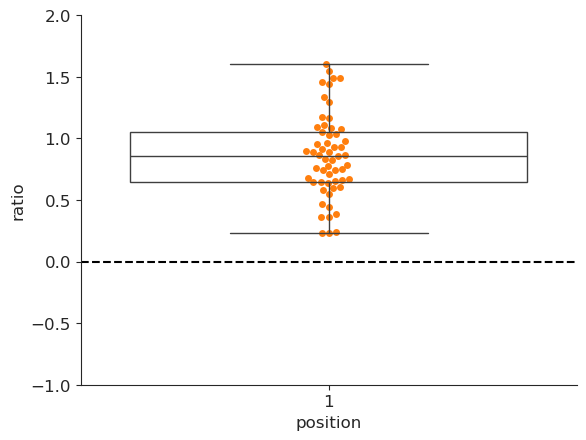

In [24]:
graph3['position'] = 1
sns.boxplot(data= graph3[graph3['sample'] == 'DI'], x="position", y="ratio",boxprops={'facecolor':'None'})
sns.swarmplot(x="position", y="ratio", data=graph3[graph3['sample'] == 'DI'], zorder=.5)
plt.axhline(y=0, color = 'k', ls='--')
plt.ylim(-1,2)
sns.despine()
stats.ttest_1samp(graph3.ratio, popmean=0)
plt.savefig(os.path.join('Figures','scRNAseq', 'coPositivity.pdf'), format='pdf', bbox_inches = "tight")


# flu and IFN

In [44]:
fluframe = []
IFNframe = []
for sample in samples:
    currFrame = samples[sample]
    sums = currFrame.groupby(['cell']).UMI.sum().reset_index().rename(columns = {'UMI':'sum'})
    flu = currFrame[currFrame.gene.isin(alternateFlu + segments)]
    flu = flu.merge(sums, on = 'cell', how='right').fillna(0)
    flu['UMI'] = flu.UMI/flu['sum']
    flu = flu.pivot_table(index = 'cell', values = 'UMI', columns = 'gene').fillna(0).reset_index()
    renames = {}
    for newname, segment in enumerate(segments):
        renames[segment] = alternateFlu[newname]
    flu = flu.rename(columns = renames)
    flu['sample'] = sample
    flu = flu.merge( currFrame[currFrame.gene.isin(alternateFlu + segments)].groupby(['cell']).UMI.sum().reset_index().rename(columns= {'UMI':'flusum'}), on='cell', how='left').fillna(0)
    flu['fluPos'] = flu.flusum > fluThresh[sample]
    flu['fluFraction'] = flu[alternateFlu].sum(axis=1)
    fluframe += [flu]

    IFN = currFrame[currFrame.gene.isin(typeI + typeIII)]
    IFN = IFN.merge(sums, on = 'cell', how='right').fillna(0)
    IFN['UMI'] = IFN.UMI/IFN['sum']
    IFN = IFN.pivot_table(index = 'cell', values = 'UMI', columns = 'gene').fillna(0).reset_index()
    IFN['sample'] = sample
    IFNframe += [IFN]


fluframe = pd.concat(fluframe)
IFNframe = pd.concat(IFNframe)
IFNframe = IFNframe.fillna(0)
IFNframe['IFNpos'] = IFNframe[['IFNB1','IL28A','IL28B','IL29']].sum(axis=1) > 0


subset deletions to flu+ cells

In [45]:
deletionFrame = deletionFrame.rename(columns={'barcode':'cell'}).merge(fluframe[fluframe.fluPos][['cell']], on='cell', how='inner')

In [46]:
deletionFrame['IFNpos'] = deletionFrame.cell.isin(IFNframe[IFNframe.IFNpos].cell)

deletion summary

In [48]:
deletionFrame[deletionFrame['count']> 2].to_csv(os.path.join('Results','scRNAseq','deletions.csv'))

IFN positive cells (low numbers but show)

In [16]:
IFNframe
contingency = pd.crosstab(IFNframe['IFNpos'],IFNframe['sample'] )
ratio, pval = scipy.stats.fisher_exact(contingency)
print(pval)


0.16428112049948929


In [19]:

contingency = pd.crosstab(IFNframe['IFNpos'],IFNframe['sample'] )
ratio, pval = scipy.stats.fisher_exact(contingency)
print(pval)

0.16428112049948929


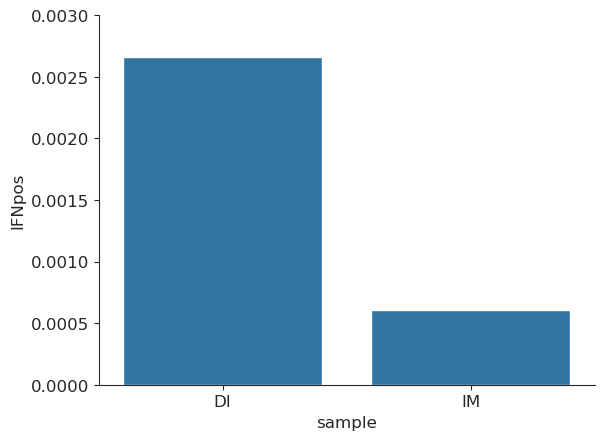

In [20]:
sns.barplot(data = IFNframe.groupby(['sample']).IFNpos.mean().reset_index(), x='sample',y='IFNpos')
sns.despine()
plt.ylim(0,0.003)
plt.savefig(os.path.join('Figures','scRNAseq', 'totIFN.pdf'), format='pdf', bbox_inches = "tight")


In [21]:
print(IFNframe.groupby(['sample']).IFNpos.sum())
print(IFNframe.groupby(['sample']).IFNpos.count())

sample
DI    7
IM    1
Name: IFNpos, dtype: int64
sample
DI    2628
IM    1639
Name: IFNpos, dtype: int64


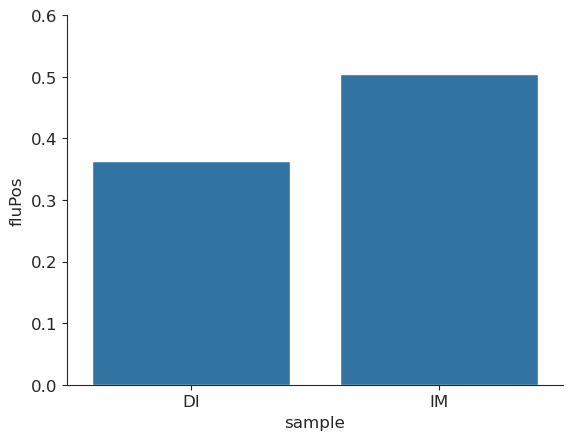

In [22]:

sns.barplot(data = fluframe.groupby(['sample']).fluPos.mean().reset_index(), x='sample',y='fluPos')
sns.despine()
plt.ylim(0,0.6)
plt.savefig(os.path.join('Figures','scRNAseq', 'totFLu.pdf'), format='pdf', bbox_inches = "tight")


In [23]:
print(fluframe.groupby(['sample']).fluPos.sum())
print(fluframe.groupby(['sample']).fluPos.count())

sample
DI    954
IM    826
Name: fluPos, dtype: int64
sample
DI    2628
IM    1639
Name: fluPos, dtype: int64


In [24]:
 fluframe.groupby(['sample']).fluPos.mean()

sample
DI    0.363014
IM    0.503966
Name: fluPos, dtype: float64

Relative flu transcripts. Use UMI and pseudobulk

/scratch/a5russell/job_11816544/ipykernel_2839549/2104238108.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  graph['fluFraction'] = np.log10(graph.fluFraction)


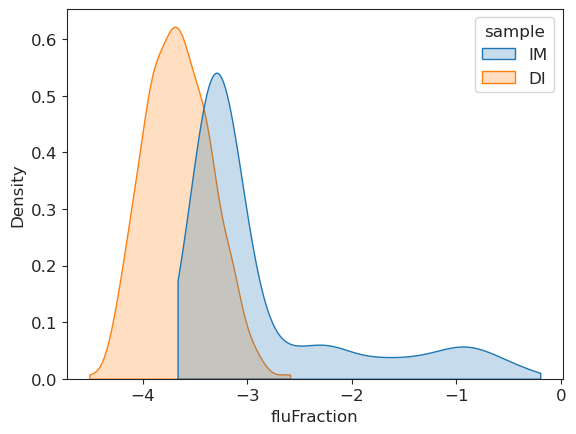

In [25]:
graph = fluframe[fluframe.fluPos]
graph['fluFraction'] = np.log10(graph.fluFraction)
sns.kdeplot(data=graph, hue='sample', x='fluFraction', cut=0, fill=True)
plt.savefig(os.path.join('Figures','scRNAseq', 'fluDist.pdf'), format='pdf', bbox_inches = "tight")


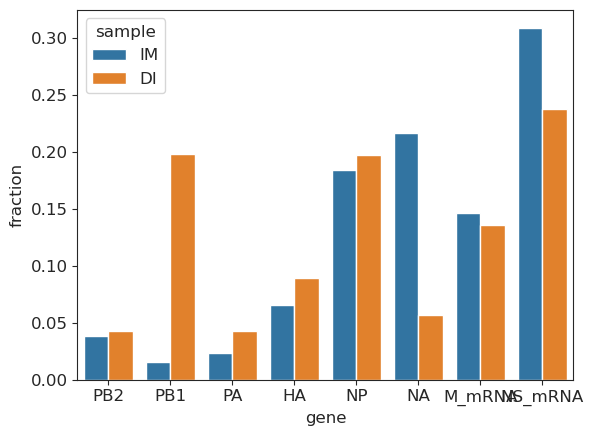

In [26]:
graph = []
for sample in samples:
    currFrame = samples[sample].copy()
    currFrame = currFrame[currFrame.gene.isin(segments)].groupby('gene').UMI.sum().reset_index()
    currFrame['fraction'] = currFrame.UMI/currFrame.UMI.sum()
    currFrame['sample'] = sample
    graph += [currFrame]
graph = pd.concat(graph)
sns.barplot(data=graph, hue='sample', x='gene', y='fraction', order=segments)
plt.savefig(os.path.join('Figures','scRNAseq', 'relfluFractpsuedobulk.pdf'), format='pdf', bbox_inches = "tight")


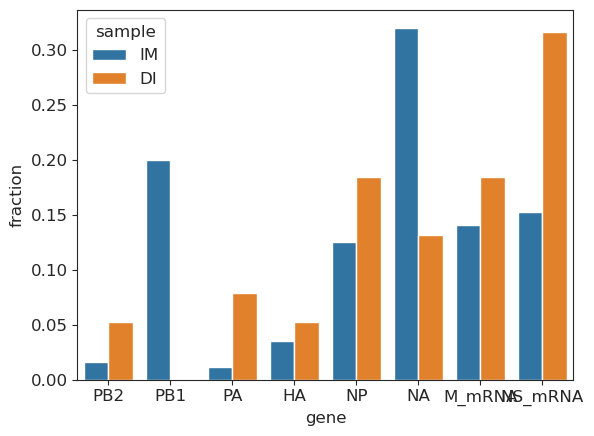

In [27]:
graph = []
for sample in samples:
    currFrame = samples[sample].copy()
    currFrame = currFrame[(currFrame.gene.isin(segments)) & (currFrame.cell.isin(IFNframe[IFNframe.IFNpos].cell))].groupby('gene').UMI.sum().reset_index()
    currFrame['fraction'] = currFrame.UMI/currFrame.UMI.sum()
    currFrame['sample'] = sample
    graph += [currFrame]
graph = pd.concat(graph)
sns.barplot(data=graph, hue='sample', x='gene', y='fraction', order=segments)
plt.savefig(os.path.join('Figures','scRNAseq', 'relfluFractpsuedobulkIFN.pdf'), format='pdf', bbox_inches = "tight")


is absence in DI of PB1 relevant? Treat each UMI in an IFN positive cell as potentially drawing from larger distrubtion reflected in IFN negative cells.

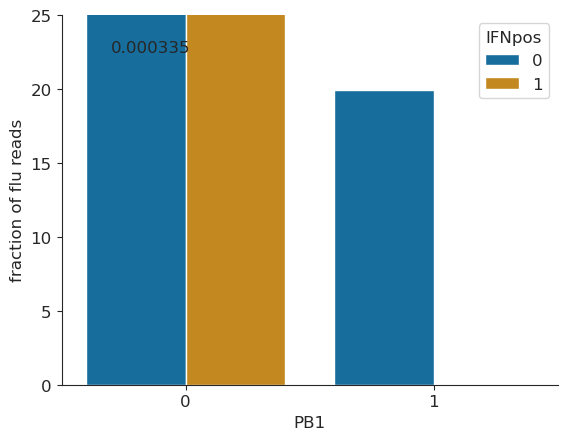

In [28]:

graph = []
for sample in ['DI']:
    currFrame = samples[sample].copy()
    currFrame = currFrame[currFrame.gene.isin(segments)]
    currFrame['IFNpos'] = currFrame.cell.isin(IFNframe[(IFNframe['sample'] == sample) & (IFNframe.IFNpos)].cell)
    #fill 0's
    currFrame = currFrame.merge(pd.DataFrame({'gene':segments*2, 'IFNpos':[False] * len(segments) + [True] * len(segments)}), on = ['gene','IFNpos'], how='right').fillna(0)

    currFrame = currFrame.groupby(['gene', 'IFNpos']).UMI.sum().reset_index()
    currFrame = currFrame.merge(currFrame.groupby('IFNpos').UMI.sum().reset_index().rename(columns={'UMI':'sum'}), on ='IFNpos')
    currFrame['sample'] = sample
    graph += [currFrame]
graph = pd.concat(graph)
graph=graph[graph.gene == 'PB1']
doubPos = int(graph[graph.IFNpos].UMI.iloc[0])
IFNnotPB1 = int(graph[graph.IFNpos]['sum'].iloc[0] - doubPos)
noIFNPB1 = int(graph[~(graph.IFNpos)].UMI.iloc[0])
noIFNnotPB1 = int(graph[~(graph.IFNpos)]['sum'].iloc[0] - noIFNPB1)
raw = pd.DataFrame({'IFNpos':[1]*(doubPos+IFNnotPB1) + [0]*(noIFNPB1+noIFNnotPB1), 'PB1':[1]*(doubPos) + [0]*(IFNnotPB1) + [1]*(noIFNPB1) + [0]*(noIFNnotPB1)})
contingency = pd.crosstab(raw.IFNpos, raw.PB1)
ratio, pval = scipy.stats.fisher_exact(contingency)
frequency = pd.crosstab(raw.IFNpos, raw.PB1, normalize='index').stack().reset_index().rename(columns={0:'value'})
frequency['value'] = frequency['value']*100
ax = sns.barplot(x= 'PB1', y='value', hue='IFNpos', palette = colors[:2],data=frequency,  hue_order= [0,1])
sns.despine()
ax.set_ylabel('fraction of flu reads')
plt.text(0.1, 0.9, f'{float(f"{pval:.3g}"):g}', transform=plt.gca().transAxes)
plt.ylim(0,25)
plt.savefig(os.path.join('Figures','scRNAseq', 'PB1absenceDIIFN.pdf'), format='pdf', bbox_inches = "tight")


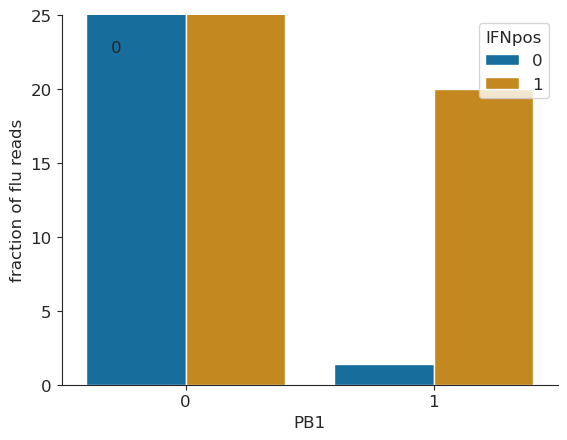

In [29]:

graph = []
for sample in ['IM']:
    currFrame = samples[sample].copy()
    currFrame = currFrame[currFrame.gene.isin(segments)]
    currFrame['IFNpos'] = currFrame.cell.isin(IFNframe[(IFNframe['sample'] == sample) & (IFNframe.IFNpos)].cell)
    #fill 0's
    currFrame = currFrame.merge(pd.DataFrame({'gene':segments*2, 'IFNpos':[False] * len(segments) + [True] * len(segments)}), on = ['gene','IFNpos'], how='right').fillna(0)

    currFrame = currFrame.groupby(['gene', 'IFNpos']).UMI.sum().reset_index()
    currFrame = currFrame.merge(currFrame.groupby('IFNpos').UMI.sum().reset_index().rename(columns={'UMI':'sum'}), on ='IFNpos')
    currFrame['sample'] = sample
    graph += [currFrame]
graph = pd.concat(graph)
graph=graph[graph.gene == 'PB1']
doubPos = int(graph[graph.IFNpos].UMI.iloc[0])
IFNnotPB1 = int(graph[graph.IFNpos]['sum'].iloc[0] - doubPos)
noIFNPB1 = int(graph[~(graph.IFNpos)].UMI.iloc[0])
noIFNnotPB1 = int(graph[~(graph.IFNpos)]['sum'].iloc[0] - noIFNPB1)
raw = pd.DataFrame({'IFNpos':[1]*(doubPos+IFNnotPB1) + [0]*(noIFNPB1+noIFNnotPB1), 'PB1':[1]*(doubPos) + [0]*(IFNnotPB1) + [1]*(noIFNPB1) + [0]*(noIFNnotPB1)})
contingency = pd.crosstab(raw.IFNpos, raw.PB1)
ratio, pval = scipy.stats.fisher_exact(contingency)
frequency = pd.crosstab(raw.IFNpos, raw.PB1, normalize='index').stack().reset_index().rename(columns={0:'value'})
frequency['value'] = frequency['value']*100
ax = sns.barplot(x= 'PB1', y='value', hue='IFNpos', palette = colors[:2],data=frequency,  hue_order= [0,1])
sns.despine()
ax.set_ylabel('fraction of flu reads')
plt.text(0.1, 0.9, f'{float(f"{pval:.3g}"):g}', transform=plt.gca().transAxes)
plt.ylim(0,25)
plt.savefig(os.path.join('Figures','scRNAseq', 'PB1presenceDIIM.pdf'), format='pdf', bbox_inches = "tight")


Raw numbers for graph

In [30]:
pval

0.0

In [32]:
pval

0.0